In [1]:
import numpy as np
from scipy import ndimage as ndi
from skimage.morphology import skeletonize, binary_dilation

def keep_junction_junction_segments(
    bw,
    do_skeletonize=False,
    min_length=0,
    include_only_touched_junctions=True,
):
    """
    Keep only skeleton segments that connect two junctions (branch points).

    Parameters
    ----------
    bw : ndarray of bool
        Binary image (True = foreground). Can be a skeleton already.
    do_skeletonize : bool, optional
        If True, skeletonize `bw` first. Default False.
    min_length : int, optional
        Discard chains shorter than this many pixels (after junction removal).
        Default 0.
    include_only_touched_junctions : bool, optional
        If True, add back only junction pixels that touch kept segments.
        If False, add back all junction pixels. Default True.

    Returns
    -------
    pruned : ndarray of bool
        Binary image containing only junction–junction segments
        (and junction pixels they touch).
    debug : dict
        Dictionary with intermediate masks (useful for inspection):
        keys: 'skeleton', 'junctions', 'chains_label', 'kept_chains_mask'
    """
    bw = bw.astype(bool)

    # 1) Skeletonize if requested
    if do_skeletonize:
        skel = skeletonize(bw)
    else:
        skel = bw.copy()

    if not skel.any():
        return skel, {
            'skeleton': skel, 'junctions': skel, 
            'chains_label': np.zeros_like(skel, dtype=int),
            'kept_chains_mask': skel
        }

    # 2) Count 8-neighbors for each skeleton pixel
    # 3x3 ones counts center too; subtract center to get neighbor count
    footprint = np.ones((3, 3), dtype=int)
    neigh_count = ndi.convolve(skel.astype(int), footprint, mode='constant', cval=0) - skel.astype(int)

    # Junctions: pixels in skeleton with >=3 neighbors
    junctions = skel & (neigh_count >= 3)

    # 3) Remove junctions to split into simple chains
    chains = skel & ~junctions

    # Optionally filter very short chain fragments immediately
    # (We’ll filter by length per component below.)
    # 8-connectivity structure for labeling
    conn8 = np.ones((3, 3), dtype=bool)

    # 4) Label chain components
    labels, nlab = ndi.label(chains, structure=conn8)
    if nlab == 0:
        # No chains (all junctions or empty)
        pruned = np.zeros_like(skel, dtype=bool)
        return pruned, {
            'skeleton': skel, 'junctions': junctions,
            'chains_label': labels, 'kept_chains_mask': pruned
        }
    
    kept_mask = np.zeros_like(skel, dtype=bool)
    touched_junctions = np.zeros_like(junctions, dtype=bool)

    # 5) For each chain: keep iff touches >= 2 junctions (via 1-pixel dilation)
    for lab_id in range(1, nlab + 1):
        comp = (labels == lab_id)
        if min_length > 0 and comp.sum() < min_length:
            continue

        # Chain touches junctions if any pixel in its 1-px neighborhood is a junction
        # Use dilation of the component to look for overlaps with junction pixels
        comp_dil = binary_dilation(comp, selem=conn8)
        touching = comp_dil & junctions

        # Count how many *distinct junction blobs* it touches (robust if junctions thicker)
        # Label junction blobs for this purpose
        # (Fast optimization: label once outside the loop; but clarity > micro-optim here)
        j_labels, j_n = ndi.label(junctions, structure=conn8)
        j_ids = np.unique(j_labels[touching])
        j_ids = j_ids[j_ids != 0]

        if len(j_ids) >= 2:
            kept_mask |= comp
            if include_only_touched_junctions:
                # Keep only the junctions that this chain touches
                touched_junctions |= touching
            else:
                # We'll add all junctions later
                pass

    # 6) Compose final image by adding back junction pixels
    if include_only_touched_junctions:
        pruned = kept_mask | touched_junctions
    else:
        pruned = kept_mask | junctions

    debug = {
        'skeleton': skel,
        'junctions': junctions,
        'chains_label': labels,
        'kept_chains_mask': kept_mask
    }
    return pruned, debug


In [7]:
from bia_bob import bob
import os
bob.initialize(endpoint="https://chat.ai.e-infra.cz/api/", model="gpt-oss-120b")

%bob open BLADDER I K DETAILS-Region 003-41 1_ skeleton.tif image using some tiff reader and show summary using the stackview. Do not use aicsimageio

We will load the TIFF file **BLADDER I K DETAILS-Region 003-41 1_ skeleton.tif** with `skimage.io.imread`, print a brief numerical summary (shape, dtype, intensity range), and visualise the stack using **stackview**.



Image summary:
  shape          : (1437, 826)
  dtype          : uint8
  intensity range: 0 – 255


[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
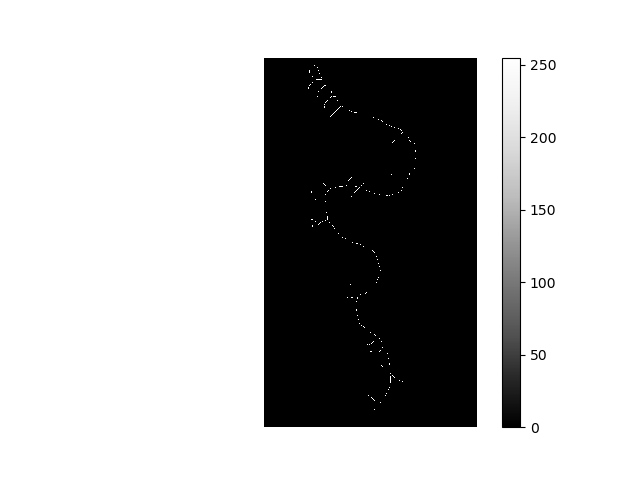
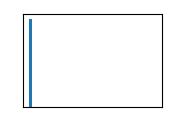

In [2]:
# 1. Imports
from skimage.io import imread
import stackview
import numpy as np  # np is already available, but importing is harmless

# 2. Path to the TIFF file (modify if needed)
tiff_path = "BLADDER I K DETAILS-Region 003-41 1_ skeleton.tif"

# 3. Load the image
img = imread(tiff_path)

# 4. Print a short summary
print("Image summary:")
print(f"  shape          : {img.shape}")
print(f"  dtype          : {img.dtype}")
print(f"  intensity range: {np.min(img)} – {np.max(img)}")

# 5. Visualise with stackview
stackview.insight(img)

In [3]:
import numpy as np
from skimage.morphology import skeletonize
from skimage.measure import label
import networkx as nx

# weights for 8-neighborhood: (dr, dc) -> cost
_OFFSETS = [(-1,-1), (-1,0), (-1,1),
            ( 0,-1),          ( 0,1),
            ( 1,-1), ( 1,0),  ( 1,1)]
_WEIGHTS = [np.sqrt(2), 1, np.sqrt(2),
            1,                1,
            np.sqrt(2), 1,    np.sqrt(2)]

def prune_to_longest_path(skel: np.ndarray, keep_per_component=False):
    """
    skel: binary skeleton (True/1 where skeleton pixels are)
    keep_per_component: if True, keeps the longest path within EACH connected component;
                        if False (default), keeps only the single longest path in the whole image.
    Returns a binary mask of the same shape with only the longest path(s) kept.
    """
    skel = skel.astype(bool)
    H, W = skel.shape
    out = np.zeros_like(skel, dtype=bool)

    # label components to handle disconnected skeletons cleanly
    lbl = label(skel, connectivity=2)
    labels = np.unique(lbl)[1:]  # skip background

    def component_longest_path_mask(comp_mask):
        # map (r,c) <-> node id
        coords = np.argwhere(comp_mask)
        id_of = { (r,c): i for i,(r,c) in enumerate(map(tuple, coords)) }
        G = nx.Graph()
        G.add_nodes_from(range(len(coords)))

        for idx,(r,c) in enumerate(coords):
            for (dr,dc), w in zip(_OFFSETS, _WEIGHTS):
                nr, nc = r+dr, c+dc
                if 0 <= nr < H and 0 <= nc < W and comp_mask[nr, nc]:
                    j = id_of[(nr,nc)]
                    if j != idx:
                        G.add_edge(idx, j, weight=w)

        if G.number_of_nodes() == 0:
            return np.zeros_like(comp_mask, dtype=bool)

        # endpoints (degree == 1)
        endpoints = [n for n,deg in G.degree() if deg == 1]

        # choose a start node
        start = endpoints[0] if endpoints else next(iter(G.nodes))

        # 1st sweep: farthest from start
        lengths = nx.single_source_dijkstra_path_length(G, start, weight='weight')
        a = max(lengths, key=lengths.get)

        # 2nd sweep: farthest from a
        lengths2, paths = nx.single_source_dijkstra(G, a, weight='weight')
        b = max(lengths2, key=lengths2.get)

        # retrieve path a->b and rasterize it
        path_nodes = paths[b]
        path_mask = np.zeros_like(comp_mask, dtype=bool)
        for n in path_nodes:
            r, c = coords[n]
            path_mask[r, c] = True
        return path_mask

    if keep_per_component:
        for k in labels:
            comp = (lbl == k)
            out |= component_longest_path_mask(comp)
    else:
        # find the single global longest path across all components
        best_len = -np.inf
        best_mask = None
        for k in labels:
            comp = (lbl == k)
            # build graph and compute path; also compute its length
            tmp_mask = component_longest_path_mask(comp)
            # approximate length as number of pixels along the path with diagonal cost accounted:
            # compute length by summing neighbor steps along the path
            coords = np.argwhere(tmp_mask)
            if coords.size == 0:
                continue
            # quick length via graph again (reuse logic)
            # get endpoints within this path
            # build tiny graph on this path to measure endpoints distance
            # (for robustness, reuse the component graph function)
            path_len = tmp_mask.sum()  # fallback proxy
            if path_len > best_len:
                best_len = path_len
                best_mask = tmp_mask
        out = best_mask if best_mask is not None else out

    return out

# Example usage:
# skel_img = ...  # your binary skeleton
# longest_path = prune_to_longest_path(skel_img, keep_per_component=False)


In [5]:
img_longest = prune_to_longest_path(img, keep_per_component=False)

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
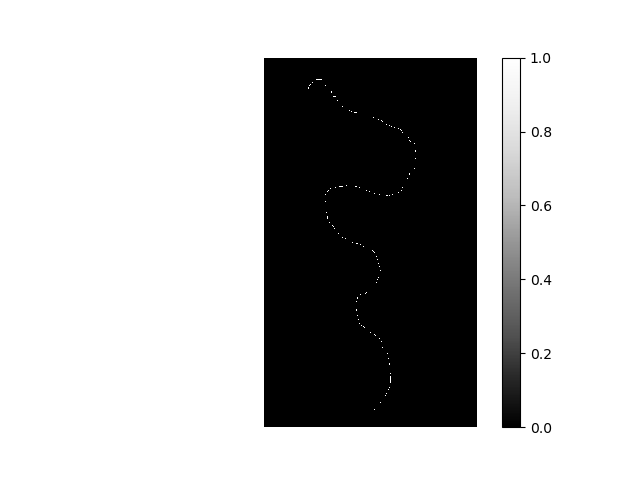
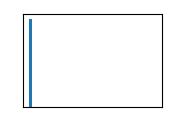

In [6]:
stackview.insight(img_longest)

In [7]:
img_DT = imread("BLADDER I K DETAILS-Region 003-41 1 DT.tif")

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
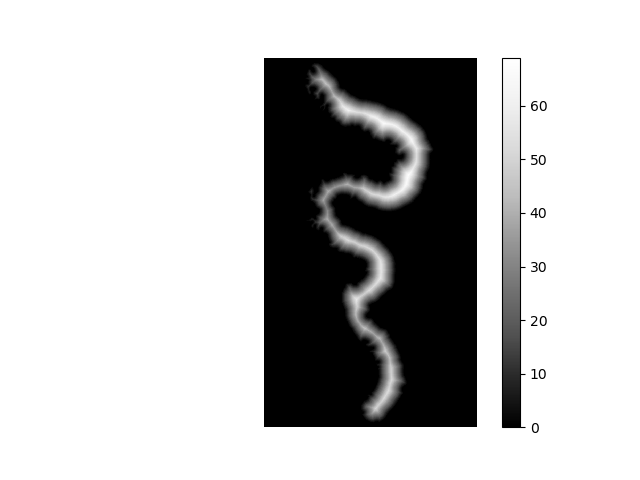
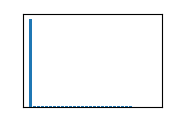

In [8]:
stackview.insight(img_DT)

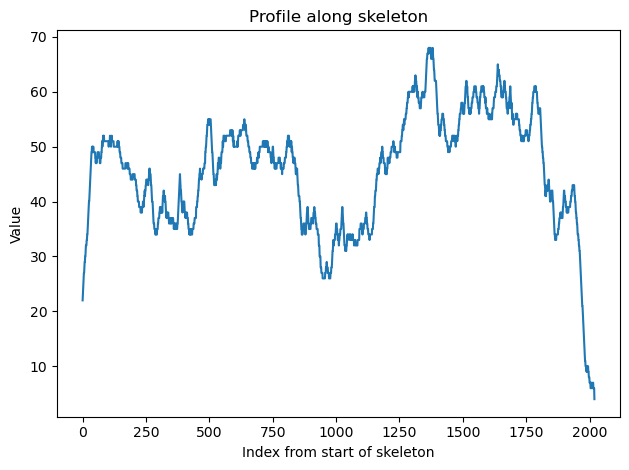

In [11]:
import numpy as np
import networkx as nx
from skimage.measure import label
import matplotlib.pyplot as plt

# 8-neighbourhood offsets + step costs
_OFF = [(-1,-1), (-1,0), (-1,1),
        ( 0,-1),         ( 0,1),
        ( 1,-1), ( 1,0), ( 1,1)]
_W   = [np.sqrt(2),1,np.sqrt(2), 1,1, np.sqrt(2),1,np.sqrt(2)]

def _component_graph(mask):
    """Build a weighted 8-connected graph for this component mask."""
    H, W = mask.shape
    coords = np.argwhere(mask)
    id_of = {tuple(rc): i for i, rc in enumerate(coords)}
    G = nx.Graph()
    G.add_nodes_from(range(len(coords)))
    for i,(r,c) in enumerate(coords):
        for (dr,dc), w in zip(_OFF, _W):
            nr, nc = r+dr, c+dc
            if 0 <= nr < H and 0 <= nc < W and mask[nr, nc]:
                j = id_of[(nr, nc)]
                if j != i:
                    G.add_edge(i, j, weight=w)
    return G, coords

def longest_ordered_path(skel):
    """
    Return the single longest geodesic path across the whole skeleton,
    as an ordered list of (row, col) coordinates from one end to the other.
    """
    skel = skel.astype(bool)
    lbl = label(skel, connectivity=2)
    best_len = -np.inf
    best_path_coords = None

    for k in np.unique(lbl)[1:]:
        comp = (lbl == k)
        G, coords = _component_graph(comp)
        if G.number_of_nodes() == 0:
            continue

        # endpoints = degree 1 (if none -> loop: pick arbitrary start)
        endpoints = [n for n,deg in G.degree() if deg == 1]
        start = endpoints[0] if endpoints else next(iter(G.nodes))

        # two-sweep Dijkstra to find diameter path
        d1 = nx.single_source_dijkstra_path_length(G, start, weight='weight')
        a = max(d1, key=d1.get)
        d2, paths = nx.single_source_dijkstra(G, a, weight='weight')
        b = max(d2, key=d2.get)
        path_nodes = paths[b]
        path_len = d2[b]

        if path_len > best_len:
            best_len = path_len
            best_path_coords = [tuple(coords[n]) for n in path_nodes]

    if best_path_coords is None:
        return []
    return best_path_coords  # [(r0,c0), (r1,c1), ..., (rN,cN)]

def profile_along_path(value_image, path_coords, use_arc_length=True):
    """
    Sample value_image at path pixels; return x (index or arc length) and values.
    """
    vals = np.array([value_image[r, c] for r, c in path_coords], dtype=float)
    if use_arc_length:
        # accumulate step costs for x-axis
        steps = [0.0]
        for (r0,c0),(r1,c1) in zip(path_coords[:-1], path_coords[1:]):
            dr, dc = abs(r1-r0), abs(c1-c0)
            steps.append(steps[-1] + (np.sqrt(2) if dr==1 and dc==1 else 1.0))
        x = np.array(steps)
    else:
        x = np.arange(len(vals))
    return x, vals

# --- Example usage ---
# skel: binary skeleton mask (already pruned to one path, or not — we’ll find the longest)
# img:  the other image whose values you want to read along the skeleton
# longest path (ordered)
path = longest_ordered_path(img_longest)
x, y = profile_along_path(img_DT, path, use_arc_length=False)  # True = arc length; False = simple index

plt.figure()
plt.plot(x, y)
plt.xlabel('Index from start of skeleton')   # or 'Arc length (px)' if use_arc_length=True
plt.ylabel('Value')
plt.title('Profile along skeleton')
plt.tight_layout()
plt.show()
